<center><h1>Xie_Chong_HW6</h1></center>

Name: Chong Xie
<br>
Github Username: cxieusc
<br>
USC ID: 6800668300

## 1. Tree-Based Methods

Import packages

In [18]:
import pandas as pd
from sklearn.impute import SimpleImputer
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

### (a) Download the APS Failure data

In [3]:
df_train = pd.read_csv("../data/aps_failure_training_set.csv", skiprows=20, na_values='na')
df_test = pd.read_csv("../data/aps_failure_test_set.csv", skiprows=20, na_values='na')

In [4]:
print("Training set shape:", df_train.shape)
df_train.head(5)

Training set shape: (60000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


In [5]:
print("Test set shape:", df_test.shape)
df_test.head(5)

Test set shape: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0.0,20.0,12.0,0.0,0.0,0.0,0.0,0.0,...,1098.0,138.0,412.0,654.0,78.0,88.0,0.0,0.0,0.0,0.0
1,neg,82,0.0,68.0,40.0,0.0,0.0,0.0,0.0,0.0,...,1068.0,276.0,1620.0,116.0,86.0,462.0,0.0,0.0,0.0,0.0
2,neg,66002,2.0,212.0,112.0,0.0,0.0,0.0,0.0,0.0,...,495076.0,380368.0,440134.0,269556.0,1315022.0,153680.0,516.0,0.0,0.0,0.0
3,neg,59816,NaN,1010.0,936.0,0.0,0.0,0.0,0.0,0.0,...,540820.0,243270.0,483302.0,485332.0,431376.0,210074.0,281662.0,3232.0,0.0,0.0
4,neg,1814,NaN,156.0,140.0,0.0,0.0,0.0,0.0,0.0,...,7646.0,4144.0,18466.0,49782.0,3176.0,482.0,76.0,0.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

The common techniques for filling mssing values are deleting missing records, median/mean filling, KNN filling.

In [6]:
df_train.isnull().sum()

class         0
aa_000        0
ab_000    46329
ac_000     3335
ad_000    14861
          ...  
ee_007      671
ee_008      671
ee_009      671
ef_000     2724
eg_000     2723
Length: 171, dtype: int64

In [7]:
df_test.isnull().sum()

class         0
aa_000        0
ab_000    12363
ac_000      926
ad_000     3981
          ...  
ee_007      192
ee_008      192
ee_009      192
ef_000      762
eg_000      762
Length: 171, dtype: int64

According to the above missing situation, I decide to use mean filling. 

In [10]:
X_train = df_train.drop(columns="class")
X_test = df_test.drop(columns="class")
y_train = df_train["class"]
y_test = df_test["class"]

imputer = SimpleImputer(strategy="mean").set_output(transform="pandas")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.fit_transform(X_test)

In [12]:
df_train_imputed = pd.concat([y_train, X_train_imputed], axis=1)
df_test_imputed = pd.concat([y_test, X_test_imputed], axis=1)

df_all_imputed = pd.concat(
    [df_train_imputed, df_test_imputed],
    ignore_index=True
)

df_all_imputed

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698.0,0.713189,2.130706e+09,280.000000,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058.0,0.713189,0.000000e+00,190620.639314,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040.0,0.713189,2.280000e+02,100.000000,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12.0,0.000000,7.000000e+01,66.000000,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874.0,0.713189,1.368000e+03,458.000000,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75995,neg,81852.0,0.772065,2.130706e+09,892.000000,0.0,0.0,0.0,0.0,0.0,...,632658.0,273242.0,510354.0,373918.0,349840.0,317840.0,960024.0,25566.0,0.0,0.0
75996,neg,18.0,0.000000,5.200000e+01,46.000000,8.0,26.0,0.0,0.0,0.0,...,266.0,44.0,46.0,14.0,2.0,0.0,0.0,0.0,0.0,0.0
75997,neg,79636.0,0.772065,1.670000e+03,1518.000000,0.0,0.0,0.0,0.0,0.0,...,806832.0,449962.0,778826.0,581558.0,375498.0,222866.0,358934.0,19548.0,0.0,0.0
75998,neg,110.0,0.772065,3.600000e+01,32.000000,0.0,0.0,0.0,0.0,0.0,...,588.0,210.0,180.0,544.0,1004.0,1338.0,74.0,0.0,0.0,0.0


#### (ii) Calculate the coefficient of variation

In [16]:
cv = lambda x: np.std(x, ddof=1) / np.mean(x)
df_cv = pd.DataFrame(df_all_imputed.drop(columns="class").agg(cv), columns = ["cv"])
df_cv

,cv
aa_000,4.328608
ab_000,2.178397
ac_000,2.167648
ad_000,206.786809
ae_000,22.293998
...,...
ee_007,4.885086
ee_008,3.335019
ee_009,5.753917
ef_000,47.925135


#### (iii) Plot a correlation matrix

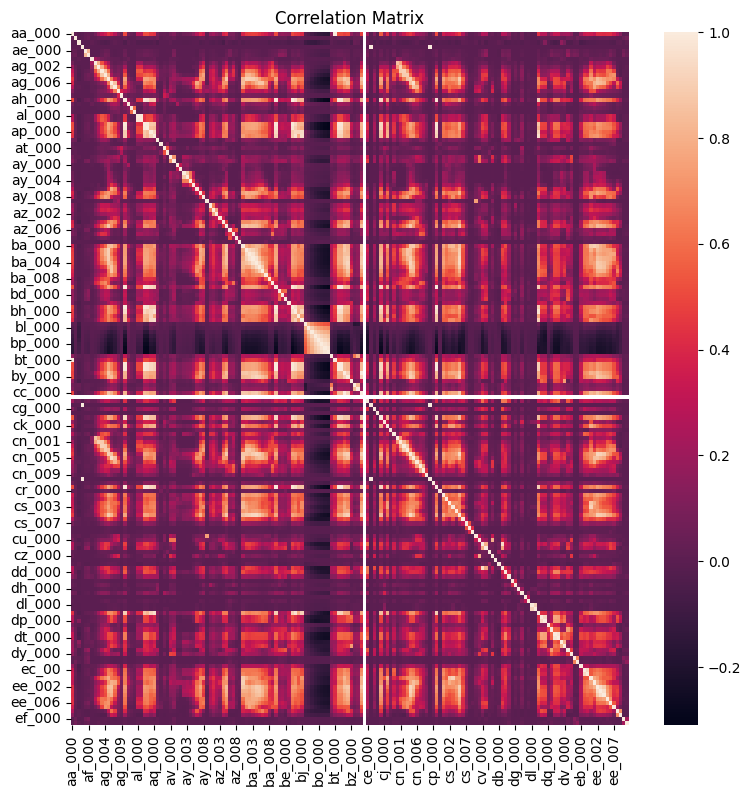

In [20]:
plt.figure(figsize=(9, 9))
sns.heatmap(df_all_imputed.drop(columns="class").corr())
plt.title("Correlation Matrix")
plt.show()

#### (iv) Make scatter plots and box plots

#### (v) Is this data set imbalanced?

### (c) Train a random forest

### (d) Research class imbalance in random forest

### (e) XGBoost and Model Trees

### (f) Use SMOTE to pre-process your data

## 2. ISLR 6.6.3

## 3. ISLR 6.6.5

## 4. ISLR 8.4.5

## 5. ISLR 9.7.3